# EnergyMind Tunisia: Phase 1 Exploratory Analysis

This notebook provides visual exploration and validation for Phase 1 of the **EnergyMind Tunisia** challenge:
1. **Normal Baseline Dynamics**: Multi-mixer production line operation (`mix_a`, `mix_b`, `mix_c`, `mix_d`).
2. **Injected Anomalies**: Visualizing genuine events (line shutdowns, surges) vs data-quality faults (drift, falsified readings, bias).
3. **Detector Evaluation**: Recall by anomaly type, confidence distribution, and automated escalation decisions.


In [2]:
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path

# Automatically find repository root (whether run from repo root or from notebooks/ folder)
REPO_ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
DATA_DIR = REPO_ROOT / "data"
RESULTS_DIR = REPO_ROOT / "results"

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (14, 5)
plt.rcParams['font.size'] = 11

clean_csv = DATA_DIR / "clean_mixers.csv"
print(f"Loading: {clean_csv}")
clean_df = pd.read_csv(clean_csv)
clean_df['time'] = pd.to_datetime(clean_df['time'])
print('Clean mixers shape:', clean_df.shape)
clean_df.head()


Loading: data/clean_mixers.csv
Clean mixers shape: (137841, 8)


,time,asset,E,L1,L2,L3,IsReliableWindow,DataCoveragePct
0,2025-01-01 00:00:00,mix_a,0.000001,0.000001,0.0,0.0,1,100.0
1,2025-01-01 00:00:00,mix_b,0.000000,0.000000,0.0,0.0,1,100.0
2,2025-01-01 00:00:00,mix_c,0.000000,0.000000,0.0,0.0,1,100.0
3,2025-01-01 00:00:00,mix_d,0.000000,0.000000,0.0,0.0,1,100.0
4,2025-01-01 00:15:00,mix_a,0.000000,0.000000,0.0,0.0,1,100.0


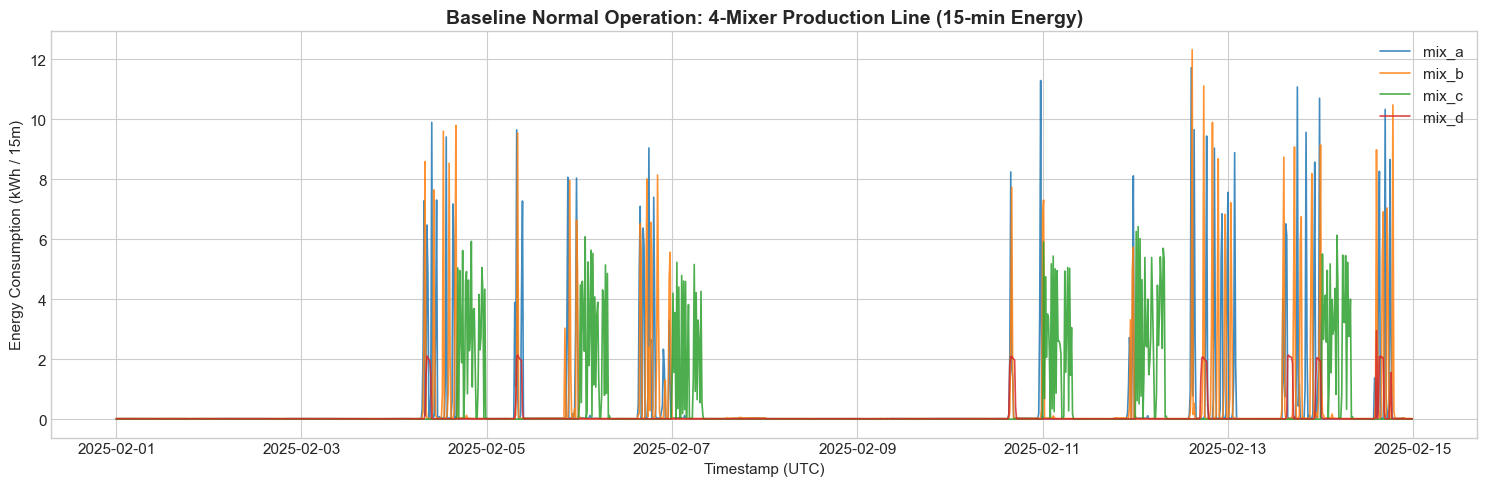

In [3]:
# 1. Normal Multi-Mixer Production Line (Two-Week Window)
pivot_e = clean_df.pivot(index='time', columns='asset', values='E')
sample_window = pivot_e.loc['2025-02-01':'2025-02-14']

plt.figure(figsize=(15, 5))
for col in sample_window.columns:
    plt.plot(sample_window.index, sample_window[col], label=f'{col}', alpha=0.85, linewidth=1.2)

plt.title('Baseline Normal Operation: 4-Mixer Production Line (15-min Energy)', fontsize=14, fontweight='bold')
plt.xlabel('Timestamp (UTC)')
plt.ylabel('Energy Consumption (kWh / 15m)')
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()


In [4]:
# 2. Inspect Injected Anomalies Log
log_csv = DATA_DIR / "anomaly_log.csv"
log_df = pd.read_csv(log_csv)
print(f'Total injected events: {len(log_df)}')
log_df[['event_id', 'type', 'group', 'asset', 'start', 'end', 'windows', 'labelled_windows', 'params']].head(10)


Total injected events: 27


,event_id,type,group,asset,start,end,windows,labelled_windows,params
0,0,shutdown,genuine_event,all,2025-11-21T09:15:00.000000000,2025-11-21T10:15:00.000000000,5,15,x0.02 on all mixers
1,1,shutdown,genuine_event,all,2025-09-21T14:15:00.000000000,2025-09-21T17:00:00.000000000,12,36,x0.02 on all mixers
2,2,shutdown,genuine_event,all,2025-12-06T12:45:00.000000000,2025-12-06T14:45:00.000000000,9,27,x0.02 on all mixers
3,3,shutdown,genuine_event,all,2025-11-07T15:15:00.000000000,2025-11-07T16:15:00.000000000,5,20,x0.02 on all mixers
4,4,surge,genuine_event,all,2025-07-19T10:00:00.000000000,2025-07-19T11:00:00.000000000,5,15,x1.6 on all mixers
5,5,surge,genuine_event,all,2025-12-27T13:00:00.000000000,2025-12-27T14:45:00.000000000,8,0,x1.6 on all mixers
6,6,drift,data_quality,mix_c,2025-11-15T22:00:00.000000000,2025-11-20T02:45:00.000000000,404,33,0 -> +40 % ramp
7,7,drift,data_quality,mix_a,2025-10-02T18:00:00.000000000,2025-10-07T02:30:00.000000000,419,360,0 -> +40 % ramp
8,8,drift,data_quality,mix_a,2025-09-07T18:00:00.000000000,2025-09-12T06:15:00.000000000,434,391,0 -> +40 % ramp
9,9,bias,data_quality,mix_b,2025-10-26T20:45:00.000000000,2025-10-29T17:00:00.000000000,274,274,x1.15


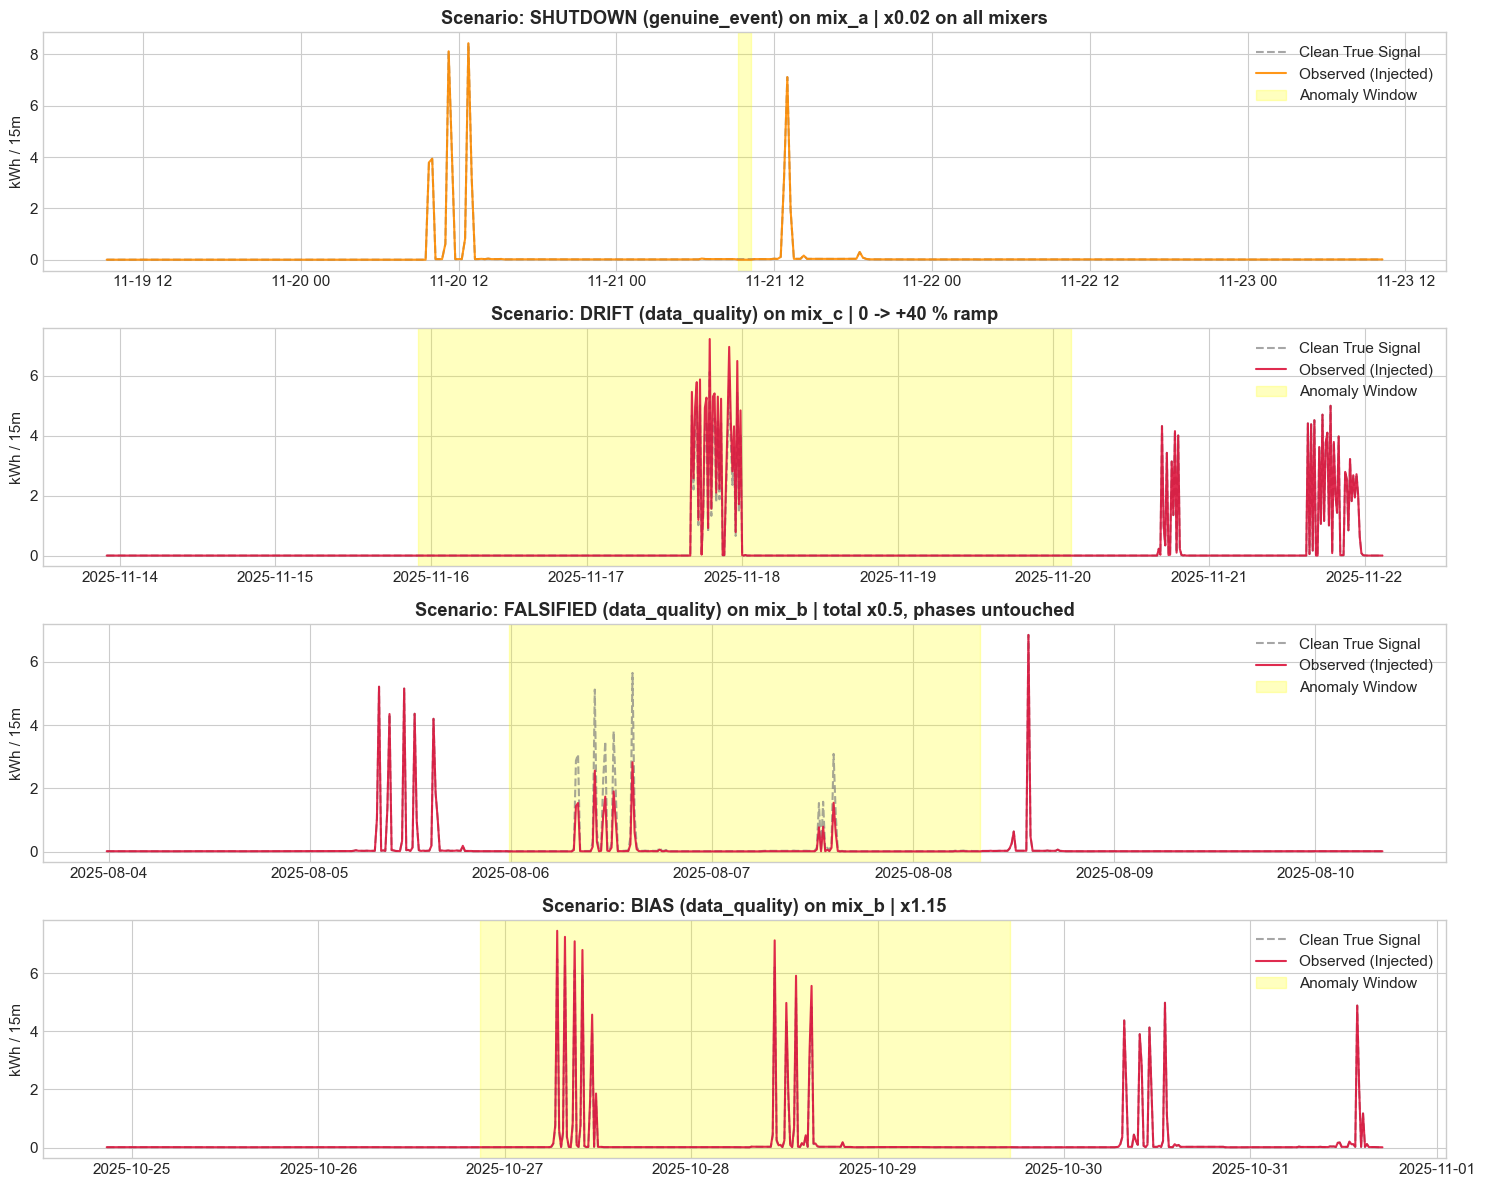

In [5]:
# 3. Visualize Injected Anomalies vs Clean Signals
inj_csv = DATA_DIR / "dataset_injected.csv"
inj_df = pd.read_csv(inj_csv)
inj_df['time'] = pd.to_datetime(inj_df['time'])

events_to_plot = [
    ('shutdown', 'genuine_event'),
    ('drift', 'data_quality'),
    ('falsified', 'data_quality'),
    ('bias', 'data_quality')
]

fig, axes = plt.subplots(len(events_to_plot), 1, figsize=(15, 12))
for ax, (atype, agroup) in zip(axes, events_to_plot):
    ev = log_df[log_df['type'] == atype].iloc[0]
    t_start = pd.to_datetime(ev['start']) - pd.Timedelta(days=2)
    t_end = pd.to_datetime(ev['end']) + pd.Timedelta(days=2)
    asset_name = ev['asset'] if ev['asset'] != 'all' else 'mix_a'
    
    sub = inj_df[(inj_df['asset'] == asset_name) & (inj_df['time'] >= t_start) & (inj_df['time'] <= t_end)]
    
    ax.plot(sub['time'], sub['E'], label='Clean True Signal', color='gray', linestyle='--', alpha=0.7)
    ax.plot(sub['time'], sub['E_obs'], label='Observed (Injected)', color='crimson' if agroup == 'data_quality' else 'darkorange', alpha=0.9)
    ax.axvspan(pd.to_datetime(ev['start']), pd.to_datetime(ev['end']), color='yellow', alpha=0.25, label='Anomaly Window')
    ax.set_title(f"Scenario: {atype.upper()} ({agroup}) on {asset_name} | {ev['params']}", fontweight='bold')
    ax.set_ylabel('kWh / 15m')
    ax.legend(loc='upper right')

plt.tight_layout()
plt.show()


{
  "precision": 0.587,
  "recall": 0.48,
  "false_positive_rate": 0.0135,
  "genuine_vs_dq_accuracy": 1.0,
  "latency_ms_per_row": 0.0091,
  "recall_by_type": {
    "bias": 0.03,
    "ct_ratio": 0.09,
    "drift": 1.0,
    "falsified": 1.0,
    "gap": 1.0,
    "phase_bias": 0.0,
    "shutdown": 0.0,
    "stuck": 0.0,
    "surge": 0.0
  },
  "flagged_windows": 2166,
  "auto_actions": 196,
  "human_reviews": 1970
}


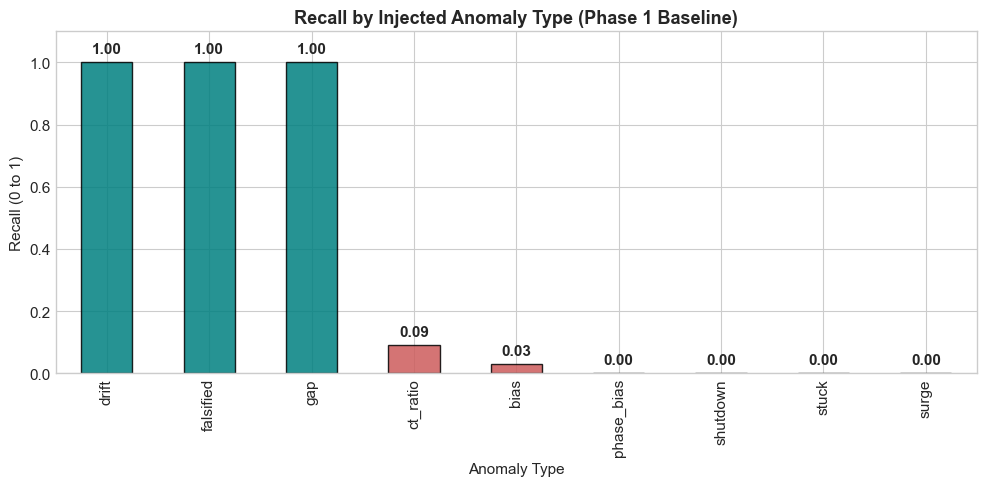

In [6]:
# 4. Evaluation Metrics & Recall by Anomaly Type
metrics_json = RESULTS_DIR / "metrics.json"
with open(metrics_json) as f:
    metrics = json.load(f)

print(json.dumps(metrics, indent=2))

recalls = pd.Series(metrics['recall_by_type']).sort_values(ascending=False)

plt.figure(figsize=(10, 5))
colors = ['teal' if v >= 0.5 else 'indianred' for v in recalls.values]
recalls.plot(kind='bar', color=colors, edgecolor='black', alpha=0.85)
plt.title('Recall by Injected Anomaly Type (Phase 1 Baseline)', fontsize=13, fontweight='bold')
plt.xlabel('Anomaly Type')
plt.ylabel('Recall (0 to 1)')
plt.ylim(0, 1.1)
for i, v in enumerate(recalls.values):
    plt.text(i, v + 0.03, f'{v:.2f}', ha='center', fontweight='bold')
plt.tight_layout()
plt.show()


Verdicts breakdown:
verdict
data_quality    2166
Name: count, dtype: int64

Actions breakdown:
action
HUMAN: low confidence, operator review                1970
AUTO: mark meter suspect, substitute peer estimate     196
Name: count, dtype: int64


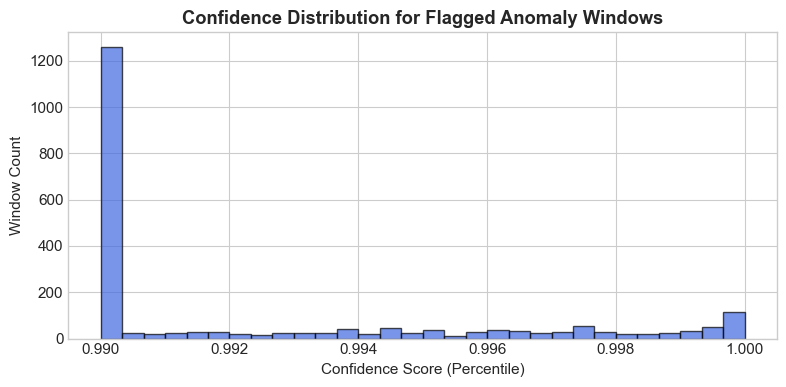

In [7]:
# 5. Decision Log Audit & Automation Breakdown
dec_csv = RESULTS_DIR / "decision_log.csv"
dec_df = pd.read_csv(dec_csv)
print('Verdicts breakdown:')
print(dec_df['verdict'].value_counts())
print('\nActions breakdown:')
print(dec_df['action'].value_counts())

plt.figure(figsize=(8, 4))
dec_df['confidence'].hist(bins=30, color='royalblue', edgecolor='black', alpha=0.7)
plt.title('Confidence Distribution for Flagged Anomaly Windows', fontweight='bold')
plt.xlabel('Confidence Score (Percentile)')
plt.ylabel('Window Count')
plt.tight_layout()
plt.show()
